In [20]:
import pandas as pd
import numpy as np


In [21]:
all_answers = []

for i in range(20):
    df = pd.read_excel(
        f"batches/to_label_iteration_{i}.xlsx",engine="openpyxl")

    # Modelov odgovor glede na verjetnosti
    df["Model"] = np.where(
        df["prob_Yes"] > df["prob_No"],
        "Yes",
        "No"
    )

    # Vzamemo samo stolpce, ki jih potrebujemo
    sample = df[[
        "SAMPLE",
        "CONTIG NAME",
        "Model",
        "Pia",
        "Lana",
        "Denis"
    ]].copy()

    # Da vemo, iz katere datoteke je prišel vzorec
    sample["iteration"] = i

    all_answers.append(sample)

# Združimo vseh 17 datotek
answers = pd.concat(all_answers, ignore_index=True)

answers

,SAMPLE,CONTIG NAME,Model,Pia,Lana,Denis,iteration
0,ERR12670267,NODE_110,Yes,No,?,No,0
1,ERR12670325,NODE_1684,Yes,No,?,No,0
2,ERR12670316,NODE_6940,No,?,No,No,0
3,ERR12670382,NODE_6981,No,No,No,No,0
4,ERR12670169,NODE_6549,Yes,No,No,No,0
...,...,...,...,...,...,...,...
564,ERR12670502,NODE_33183,Yes,Yes,Yes,yes,19
565,ERR12670416,NODE_156124,No,No,No,no,19
566,ERR12670414,NODE_86262,Yes,Yes,Yes,yes,19
567,ERR12670509,NODE_67122,No,No,No,no,19


In [22]:
for col in ["Model", "Pia", "Lana", "Denis"]:
    print("\n", col)
    print(answers[col].value_counts(dropna=False))


 Model
Model
No     367
Yes    202
Name: count, dtype: int64

 Pia
Pia
No       385
Yes      131
?         32
no         8
Yes?       5
yes        5
Yes ?      1
 No        1
No?        1
Name: count, dtype: int64

 Lana
Lana
No     366
Yes    197
?        6
Name: count, dtype: int64

 Denis
Denis
no     234
yes    135
No     122
Yes     46
?       32
Name: count, dtype: int64


In [23]:
# ============================================================
# CLEAN ANNOTATIONS
# ============================================================

annotators = ["Pia", "Lana", "Denis"]

for col in annotators:
    answers[col] = (
        answers[col]
        .astype("string")
        .str.strip()
        .str.capitalize()
    )

# Veljavni sta samo popolnoma jasni oznaki Yes in No.
# Yes?, No?, ?, prazne vrednosti itd. bodo kasneje izločene.

In [24]:
answers["ID"] = (
    answers["SAMPLE"].astype(str)
    + "_"
    + answers["CONTIG NAME"].astype(str)
)

In [25]:
model_yes = set(answers.loc[answers["Model"] == "Yes", "ID"])
pia_yes   = set(answers.loc[answers["Pia"] == "Yes", "ID"])
lana_yes  = set(answers.loc[answers["Lana"] == "Yes", "ID"])
denis_yes = set(answers.loc[answers["Denis"] == "Yes", "ID"])

In [26]:
print("Model:", len(model_yes))
print("Pia:", len(pia_yes))
print("Lana:", len(lana_yes))
print("Denis:", len(denis_yes))

Model: 198
Pia: 136
Lana: 197
Denis: 181


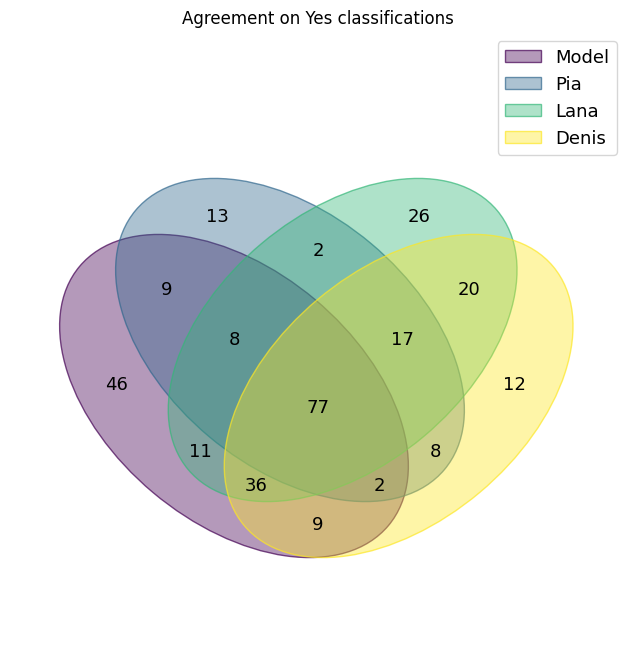

In [27]:
from venn import venn
import matplotlib.pyplot as plt

sets = {
    "Model": model_yes,
    "Pia": pia_yes,
    "Lana": lana_yes,
    "Denis": denis_yes
}

venn(sets)

plt.title("Agreement on Yes classifications")
plt.show()

In [28]:
model_no = set(answers.loc[answers["Model"] == "No", "ID"])
pia_no  = set(answers.loc[answers["Pia"] == "No", "ID"])
lana_no  = set(answers.loc[answers["Lana"] == "No", "ID"])
denis_no = set(answers.loc[answers["Denis"] == "No", "ID"])

In [29]:
print("Model:", len(model_no))
print("Pia:", len(pia_no))
print("Lana:", len(lana_no))
print("Denis:", len(denis_no))

Model: 364
Pia: 386
Lana: 360
Denis: 350


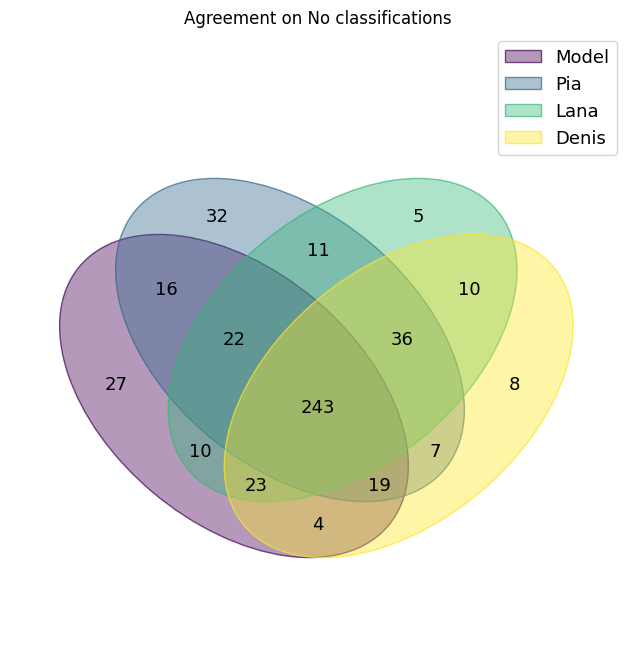

In [30]:
from venn import venn
import matplotlib.pyplot as plt

sets = {
    "Model": model_no,
    "Pia": pia_no,
    "Lana": lana_no,
    "Denis": denis_no
}

venn(sets)

plt.title("Agreement on No classifications")
plt.show()

In [31]:
from itertools import combinations

people = ["Model", "Pia", "Lana", "Denis"]

for a, b in combinations(people, 2):
    valid = answers[[a, b]].dropna()
    valid = valid[
        valid[a].isin(["Yes", "No"]) &
        valid[b].isin(["Yes", "No"])
    ]

    agreement = (valid[a] == valid[b]).mean() * 100

    print(
        f"{a} vs {b}: "
        f"{agreement:.1f}% agreement "
        f"({(valid[a] == valid[b]).sum()}/{len(valid)})"
    )

Model vs Pia: 75.3% agreement (399/530)
Model vs Lana: 76.4% agreement (430/563)
Model vs Denis: 77.5% agreement (416/537)
Pia vs Lana: 80.3% agreement (421/524)
Pia vs Denis: 82.8% agreement (414/500)
Lana vs Denis: 87.6% agreement (465/531)


In [32]:
expert_consensus = []

for i in sorted(answers["iteration"].unique()):

    temp = answers[answers["iteration"] == i].copy()

    # samo primeri, kjer imajo vsi trije jasen Yes/No
    temp = temp[
        temp["Pia"].isin(["Yes", "No"]) &
        temp["Lana"].isin(["Yes", "No"]) &
        temp["Denis"].isin(["Yes", "No"])
    ]

    # vsi trije se strinjajo
    agree = (
        (temp["Pia"] == temp["Lana"]) &
        (temp["Pia"] == temp["Denis"])
    )

    expert_consensus.append({
        "iteration": i,
        "n": len(temp),
        "all_agree": agree.sum(),
        "consensus_percent": agree.mean() * 100
    })

consensus_df = pd.DataFrame(expert_consensus)

consensus_df

,iteration,n,all_agree,consensus_percent
0,0,17,14,82.352941
1,1,17,14,82.352941
2,2,16,10,62.500000
3,3,15,12,80.000000
4,4,26,22,84.615385
5,5,25,20,80.000000
6,6,27,23,85.185185
7,7,23,17,73.913043
8,8,23,16,69.565217
9,9,25,22,88.000000


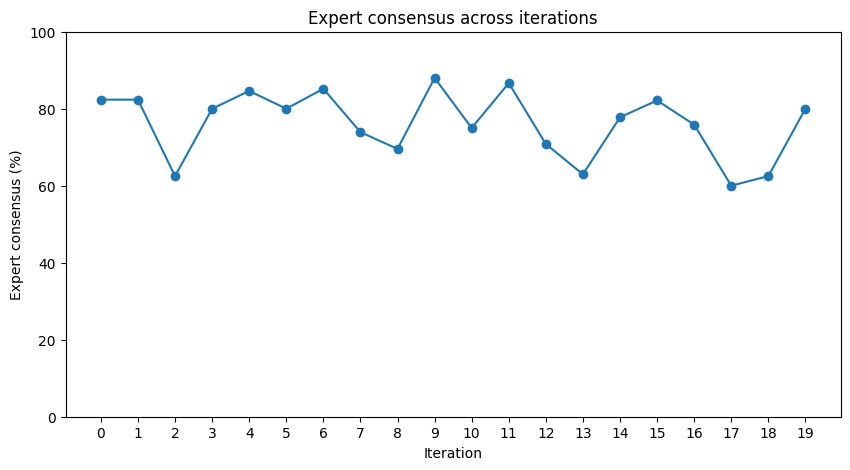

In [33]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    consensus_df["iteration"],
    consensus_df["consensus_percent"],
    marker="o"
)

plt.xlabel("Iteration")
plt.ylabel("Expert consensus (%)")
plt.title("Expert consensus across iterations")
plt.xticks(consensus_df["iteration"])
plt.ylim(0, 100)

plt.show()

In [34]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    cohen_kappa_score
)

annotators = ["Pia", "Lana", "Denis"]

pairwise_results = []


for reference in annotators:

    for annotator in annotators:

        # Ne primerjamo anotatorja s samim sabo
        if reference == annotator:
            continue

        # Uporabimo samo primere, kjer imata oba
        # jasno oznako Yes ali No
        pair = answers[
            answers[reference].isin(["Yes", "No"]) &
            answers[annotator].isin(["Yes", "No"])
        ].copy()

        # Referenčne oznake
        y_true = pair[reference].map({
            "No": 0,
            "Yes": 1
        })

        # Oznake drugega anotatorja
        y_pred = pair[annotator].map({
            "No": 0,
            "Yes": 1
        })

        # ----------------------------------------------------
        # Metrics
        # ----------------------------------------------------

        agreement = (
            y_true == y_pred
        ).mean()

        kappa = cohen_kappa_score(
            y_true,
            y_pred
        )

        accuracy = accuracy_score(
            y_true,
            y_pred
        )

        precision = precision_score(
            y_true,
            y_pred,
            zero_division=0
        )

        recall = recall_score(
            y_true,
            y_pred,
            zero_division=0
        )

        f1 = f1_score(
            y_true,
            y_pred,
            zero_division=0
        )

        pairwise_results.append({
            "reference": reference,
            "annotator": annotator,
            "n": len(pair),
            "agreement": agreement,
            "cohen_kappa": kappa,
            "accuracy": accuracy,
            "precision": precision,
            "recall": recall,
            "f1": f1
        })


pairwise_df = pd.DataFrame(
    pairwise_results
)

print(
    pairwise_df.round(3)
)

  reference annotator    n  agreement  cohen_kappa  accuracy  precision  \
0       Pia      Lana  524      0.803        0.533     0.803      0.584   
1       Pia     Denis  500      0.828        0.589     0.828      0.627   
2      Lana       Pia  524      0.803        0.533     0.803      0.782   
3      Lana     Denis  531      0.876        0.725     0.876      0.847   
4     Denis       Pia  500      0.828        0.589     0.828      0.812   
5     Denis      Lana  531      0.876        0.725     0.876      0.794   

   recall     f1  
0   0.782  0.669  
1   0.812  0.707  
2   0.584  0.669  
3   0.794  0.820  
4   0.627  0.707  
5   0.847  0.820  


In [35]:
from itertools import combinations
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    cohen_kappa_score
)

annotators = ["Model","Pia", "Lana", "Denis"]

pairwise_results = []

# Vsak par samo enkrat
for reference, annotator in combinations(annotators, 2):

    # Uporabimo samo primere, kjer imata oba
    # jasno oznako Yes ali No
    pair = answers[
        answers[reference].isin(["Yes", "No"]) &
        answers[annotator].isin(["Yes", "No"])
    ].copy()

    # Referenčni anotator
    y_true = pair[reference].map({
        "No": 0,
        "Yes": 1
    })

    # Drugi anotator
    y_pred = pair[annotator].map({
        "No": 0,
        "Yes": 1
    })

    # Metrics
    agreement = (y_true == y_pred).mean()

    kappa = cohen_kappa_score(
        y_true,
        y_pred
    )

    precision = precision_score(
        y_true,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_true,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        y_pred,
        zero_division=0
    )

    pairwise_results.append({
        "Reference": reference,
        "Annotator": annotator,
        "N": len(pair),
        "Agreement": agreement,
        "Cohen's κ": kappa,
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1
    })


pairwise_df = pd.DataFrame(pairwise_results)

print(pairwise_df.round(3))

  Reference Annotator    N  Agreement  Cohen's κ  Precision  Recall  F1-score
0     Model       Pia  530      0.753      0.423      0.706   0.513     0.594
1     Model      Lana  563      0.764      0.483      0.670   0.660     0.665
2     Model     Denis  537      0.775      0.501      0.685   0.660     0.672
3       Pia      Lana  524      0.803      0.533      0.584   0.782     0.669
4       Pia     Denis  500      0.828      0.589      0.627   0.812     0.707
5      Lana     Denis  531      0.876      0.725      0.847   0.794     0.820
